# 09 - Text quality and the cliff effect (Task 1c)
**Objective.** Measure *what the user actually reads*: BLEU, word accuracy and sentence-embedding cosine similarity of the reconstructed text versus SNR, and explain the cliff effect with measured numbers.

## Metrics (as implemented in `task1_conventional/metrics.py`)
* **BLEU** - sacreBLEU sentence BLEU (up to 4-grams, 13a tokenisation, exponential smoothing), scaled to 0-1; identical sentences = 1.
* **Word accuracy** - minimum-edit-distance alignment of reference and hypothesis words (whitespace tokens). With $H$ hits, $S$ substitutions, $D$ deletions, $I$ insertions and $N=H+S+D$ reference words: **word accuracy $=H/N$**. A substituted or deleted word is a miss; an inserted word is not a hit and does not change $H/N$ but is visible in $\text{WER}=(S+D+I)/N$.
* **Cosine similarity of sentence embeddings** - the active backend is printed below. Default: mean of pretrained spaCy `en_core_web_md` word vectors (a *pretrained embedding*, not a lexical-overlap metric, but weaker than a transformer sentence encoder; unknown/garbled tokens count as zero vectors).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


In [2]:
from task1_conventional import experiments as ex, plotting
MODE = ex.best_available_mode(ROOT)      # "full" once `python main.py --experiment all --mode full` has finished
# MODE = "quick"                         # <- uncomment to force the small debugging data set
print("Using", MODE.upper(), "results", "" if MODE == "full" else "(QUICK MODE: small sample, NOT final results)")
sweep = pd.read_csv(TAB / f"{MODE}_mcs_sweep.csv")
cfg = ex.CONFIG[MODE]
print(f"{len(sweep)} (channel, MCS, SNR) points; {cfg['n_sentences']} sentences x {cfg['reps_awgn']} (AWGN) / {cfg['reps_rayleigh']} (Rayleigh) repetitions per point")

Using FULL results 
528 (channel, MCS, SNR) points; 2000 sentences x 3 (AWGN) / 5 (Rayleigh) repetitions per point


In [3]:
from task1_conventional.metrics import SentenceEmbedder
print("embedding backend used for the stored results:", ex.json.loads((ROOT / "results/logs" / f"{MODE}_config.json").read_text())["embedder"])

embedding backend used for the stored results: spacy-en_core_web_md-mean-word-vectors


## 1. Quality vs SNR

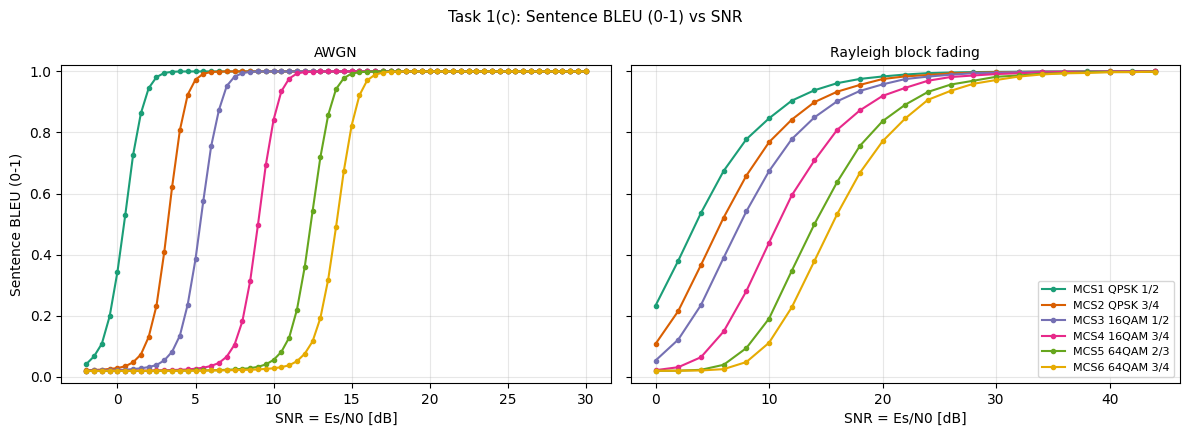

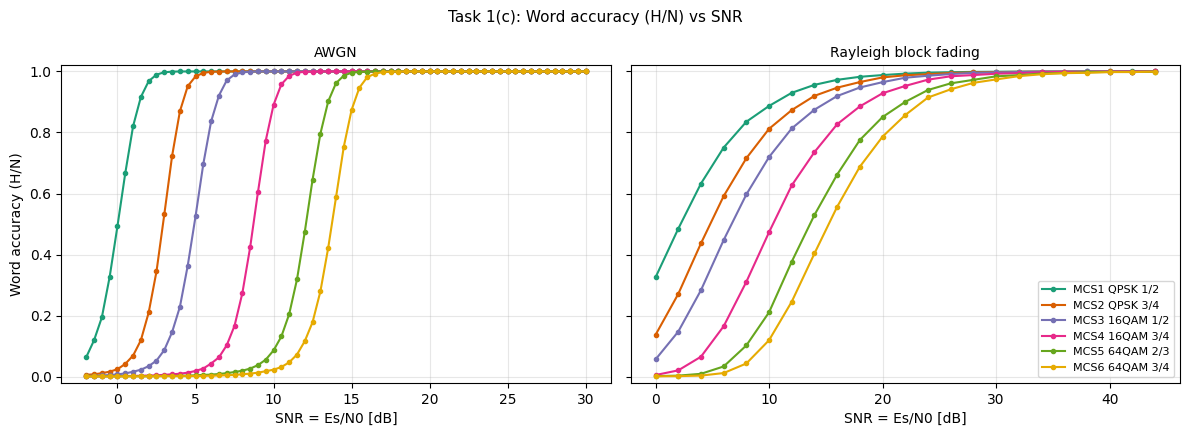

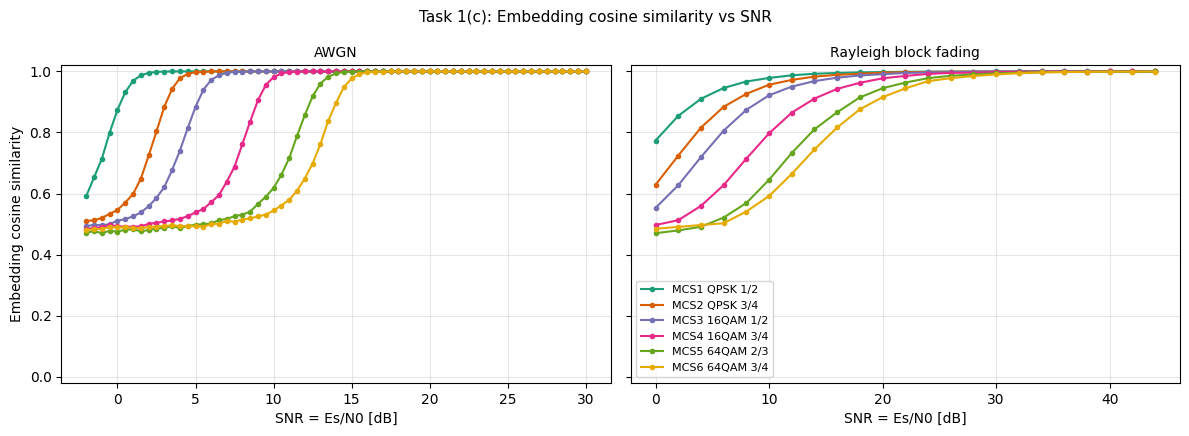

In [4]:
figs = plotting.plot_text_quality(sweep, MODE, str(FIG / MODE)); plt.show()

## 2. The cliff effect with numbers

In [5]:
def snr_at(d, col, target, rising=False):
    d = d.sort_values("snr_db"); s, v = d.snr_db.values, d[col].values
    k = np.flatnonzero(v >= target) if rising else np.flatnonzero(v <= target)
    if len(k) == 0: return np.nan
    k = k[0]
    if k == 0: return float(s[0])
    return float(s[k - 1] + (v[k - 1] - target) / (v[k - 1] - v[k]) * (s[k] - s[k - 1]))
rows = []
for chn in ("awgn", "rayleigh"):
    for m in sorted(sweep.mcs.unique()):
        d = sweep[(sweep.channel == chn) & (sweep.mcs == m)]
        s90, s10, s1 = snr_at(d, "bler", 0.9), snr_at(d, "bler", 0.1), snr_at(d, "bler", 0.01)
        rows.append(dict(channel=chn, MCS=plotting.LABEL[m], SNR_BLER90=s90, SNR_BLER10=s10, SNR_BLER1=s1, cliff_width_90_to_10_dB=s10 - s90, cliff_width_10_to_1_dB=s1 - s10))
cliff = pd.DataFrame(rows).round(2); display(cliff); cliff.to_csv(TAB / f"{MODE}_cliff_widths.csv", index=False)
aw = cliff[cliff.channel == "awgn"]
print("AWGN: BLER falls from 90 %% to 10 %% within %.1f-%.1f dB (median %.1f dB) for the six MCSs." % (aw.cliff_width_90_to_10_dB.min(), aw.cliff_width_90_to_10_dB.max(), aw.cliff_width_90_to_10_dB.median()))

,channel,MCS,SNR_BLER90,SNR_BLER10,SNR_BLER1,cliff_width_90_to_10_dB,cliff_width_10_to_1_dB
0,awgn,MCS1 QPSK 1/2,0.27,2.36,3.32,2.09,0.96
1,awgn,MCS2 QPSK 3/4,2.99,4.95,5.89,1.96,0.94
2,awgn,MCS3 16QAM 1/2,5.11,7.28,8.33,2.17,1.05
3,awgn,MCS4 16QAM 3/4,8.65,10.87,11.91,2.23,1.04
4,awgn,MCS5 64QAM 2/3,12.03,14.34,15.46,2.31,1.13
5,awgn,MCS6 64QAM 3/4,13.58,15.94,17.11,2.36,1.17
6,rayleigh,MCS1 QPSK 1/2,2.13,16.06,25.90,13.93,9.84
7,rayleigh,MCS2 QPSK 3/4,3.50,17.84,27.83,14.34,9.99
8,rayleigh,MCS3 16QAM 1/2,4.82,19.31,29.12,14.49,9.81
9,rayleigh,MCS4 16QAM 3/4,7.15,21.46,31.67,14.31,10.22


AWGN: BLER falls from 90 % to 10 % within 2.0-2.4 dB (median 2.2 dB) for the six MCSs.


### One MCS in detail: BER, BLER and text quality on the same SNR axis

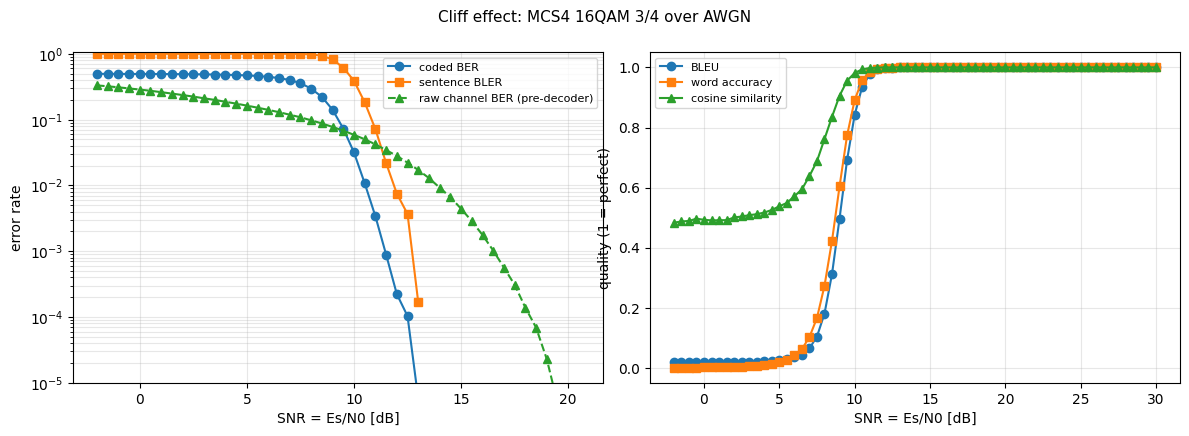

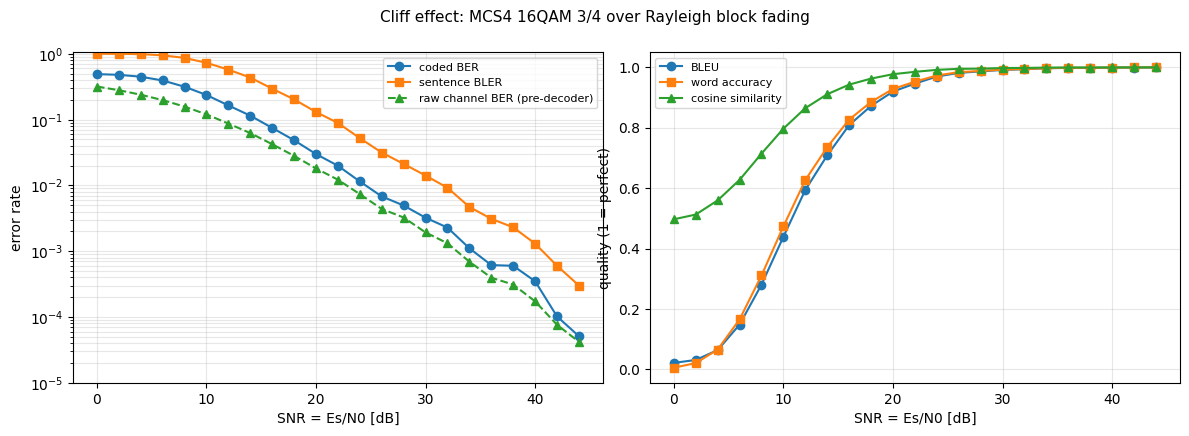

,snr_db,raw_ber,coded_ber,bler,bleu,word_acc,cos
213,7.0,0.1186,0.3984,0.9980,0.0653,0.1027,0.6385
214,7.5,0.1083,0.3582,0.9937,0.1045,0.1666,0.6880
215,8.0,0.0974,0.2952,0.9792,0.1810,0.2733,0.7617
216,8.5,0.0874,0.2215,0.9330,0.3127,0.4235,0.8358
217,9.0,0.0772,0.1412,0.8200,0.4973,0.6044,0.9056
218,9.5,0.0680,0.0730,0.6158,0.6921,0.7736,0.9556
219,10.0,0.0586,0.0317,0.3883,0.8414,0.8905,0.9814
220,10.5,0.0502,0.0108,0.1832,0.9350,0.9577,0.9933
221,11.0,0.0420,0.0034,0.0717,0.9766,0.9853,0.9978
222,11.5,0.0343,0.0009,0.0218,0.9934,0.9960,0.9993


In [6]:
for chn in ("awgn", "rayleigh"):
    plotting.plot_cliff(sweep, 4, MODE, FIG / f"{MODE}_cliff_mcs4_{chn}.png", chn); plt.show()
d = sweep[(sweep.channel == "awgn") & (sweep.mcs == 4)].sort_values("snr_db")
zone = d[(d.bler > 0.001) & (d.bler < 0.999)][["snr_db", "raw_ber", "coded_ber", "bler", "bleu", "word_acc", "cos"]]
display(zone.round(4))

### Why is there a cliff? (explanation, with the measured evidence above)
1. **Viterbi decoding has a sharp threshold.** Above a critical $E_s/N_0$ the channel errors are sparse and the code corrects *all* of them (BER $\approx0$); below it, error events become long bursts and the decoder fails over many bits at once. The coded-BER curve therefore drops over only a few dB (table above: raw channel BER changes slowly while coded BER collapses).
2. **Source coding amplifies errors.** The Huffman stream has almost no redundancy left, and a prefix code loses synchronisation after a single wrong bit - the remainder of the sentence becomes garbage. So *any* residual bit error makes the sentence wrong (BLER) and a burst of errors destroys most of it (BLEU, word accuracy $\to0$).
3. **Sentence metrics are thresholded versions of the BER.** If bit errors were independent, BLER$\approx 1-(1-\text{BER})^{N}$ for $N\approx$ 350 bits would already be a steep function of BER (a 10x BER change, $10^{-4}\to10^{-3}$, moves BLER from ~3 % to ~30 %); real Viterbi errors come in bursts, which makes the transition even sharper in SNR.
4. Hence a **small SNR change (a few dB) flips the user experience from perfect to unusable**, and the SNR margin needed for reliable text is much larger than the margin for a given BER. Compare the *cliff width* columns above with the spacing between the MCS thresholds printed in notebook 08.
5. In Rayleigh fading the cliff is *smeared* (much wider) because the SNR of each RB is random; the sentence succeeds only when none of its RBs fades deeply.

### The embedding metric is not the same cliff
Cosine similarity degrades **more gracefully** and has a high floor. Let us measure that floor instead of guessing:

In [7]:
import itertools
from task1_conventional.dataset import load_split
test = load_split("test", ROOT / "data"); rng = np.random.default_rng(0)
emb = SentenceEmbedder(); idx = rng.permutation(len(test))[:400]
rand_cos = emb.cosine([test[i] for i in idx[:200]], [test[i] for i in idx[200:]])
print("embedding backend:", emb.backend)
print("cosine similarity between RANDOM UNRELATED test sentences: mean %.3f, 5-95 %% range [%.3f, %.3f]" % (rand_cos.mean(), *np.percentile(rand_cos, [5, 95])))
low = sweep[(sweep.snr_db == sweep.snr_db.min()) & (sweep.channel == "awgn")][["mcs", "bleu", "word_acc", "cos"]]
print("At the lowest AWGN SNR in the sweep (complete garbage):"); display(low.round(3))
print("-> cosine similarity of garbled text stays near the unrelated-sentence baseline (>0), while BLEU / word accuracy go to ~0.")

embedding backend: spacy-en_core_web_md-mean-word-vectors
cosine similarity between RANDOM UNRELATED test sentences: mean 0.797, 5-95 % range [0.630, 0.911]
At the lowest AWGN SNR in the sweep (complete garbage):


,mcs,bleu,word_acc,cos
0,1,0.041,0.064,0.592
65,2,0.021,0.006,0.510
130,3,0.020,0.002,0.493
195,4,0.019,0.001,0.483
260,5,0.018,0.001,0.472
325,6,0.019,0.001,0.481


-> cosine similarity of garbled text stays near the unrelated-sentence baseline (>0), while BLEU / word accuracy go to ~0.


**Interpretation.** Mean-pooled word vectors share a large common component, so even unrelated sentences have a clearly positive cosine; garbled text is no worse than that. Cosine similarity is therefore only informative *above* this baseline and should be read together with BLEU/word accuracy. A transformer sentence encoder (`all-MiniLM-L6-v2`, used automatically when available) has a lower baseline.

## 3. Examples of reconstructed text (MCS4, AWGN)

In [8]:
from task1_conventional.dataset import load_split
from task1_conventional.huffman import HuffmanCodec
from task1_conventional.communication_system import MCS_TABLE, ConventionalLink, Frames
from task1_conventional.metrics import text_quality
codec = HuffmanCodec.from_corpus(load_split("train", ROOT / "data")); fr = Frames.build(test[10:13], codec)
link = ConventionalLink(codec, MCS_TABLE[3], "awgn")
for snr in (8.0, 9.0, 10.0, 12.0):
    res, hyp = link.run(fr, snr, np.random.default_rng(int(snr * 10)))
    q = text_quality(fr.sentences, hyp, emb)
    print(f"--- {snr} dB: BER={res.ber:.3f}")
    for a, b, bl, wa, c in zip(fr.sentences, hyp, q["bleu"], q["word_acc"], q["cos"]):
        print(f"  REF: {a}\n  HYP: {b}\n       BLEU={bl:.2f} word-acc={wa:.2f} cos={c:.2f}")

--- 8.0 dB: BER=0.287
  REF: Similar payroll tax boosts would be imposed on those under the railroad retirement system.
  HYP: Similar payroll tax boosts would be imhariiio,u cim h s bgnr urss) ae o s,teob  in.me
       BLEU=0.21 word-acc=0.43 cos=0.80
  REF: Both figures would go higher in later years.
  HYP: Bot  nlef eoniamto maeaoneds srooeibm ee  c atr
       BLEU=0.00 word-acc=0.00 cos=0.01
  REF: It is a program of prepayment of health costs with absolute freedom of choice guaranteed.
  HYP: Iakopoutnt h lba olg eirooll t r health costs with absolb eet orrohg hIseutta guaranteed.
       BLEU=0.11 word-acc=0.27 cos=0.70
--- 9.0 dB: BER=0.228
  REF: Similar payroll tax boosts would be imposed on those under the railroad retirement system.
  HYP: Similar payofsnh aneroyon  elo dr oskkaagb i?rxIrnaender the railroad retirement system.
       BLEU=0.26 word-acc=0.36 cos=0.87
  REF: Both figures would go higher in later years.
  HYP: Both figures would go higher in later years.
      